# Sri Lanka Rainfall Prediction Using Ensemble Learning
**Minor hands-on project — Bagging, Boosting, Stacking**  
**Problem:** Given weather observations at day **T** in a Sri Lankan district, predict whether precipitation on **T+1** will be at least **1 mm**.

**Important:** This notebook uses an **actual third-party Sri Lankan dataset**, never a simulated replacement. Train 2020–2023, validation 2024, final holdout test 2025. All model scores are calculated during execution rather than pre-filled. The data preparation and ensemble model definitions are included in this notebook so it can run without the separate `data_utils.py` or `modeling.py` files.

**Dataset source:** [Lahirulakshan129 / SriLanka-Weather-Dataset (GitHub)](https://github.com/Lahirulakshan129/SriLanka-Weather-Dataset); public file `SriLanka_Weather_2020_2025.csv`. The publisher does not describe upstream provenance or reuse license; confirm both before republishing data. Attribution here is academic, not a representation of licensing permission.

**AI attribution:** OpenAI ChatGPT (GPT-6, accessed 22 Nov 2026) assisted with code and dashboard drafting. All code and interpretations must be reviewed, and the video explanation must be in the student's own words. Code cells and supporting methodology were developed with AI assistance. See the AI disclosure below and, if you submit the full project, `AI_DISCLOSURE.md`.

## 1. Set up packages and imports
Run all notebook cells in order. For a new environment, the package installation command installs dependencies. The notebook will download the attributed Sri Lankan weather CSV on first run, so an internet connection is needed the first time.


In [1]:
# AI-assisted code: OpenAI ChatGPT (GPT-6), 22 November 2026.
# Review and understand this implementation before submission.
%pip install -q numpy pandas matplotlib scikit-learn requests joblib

from pathlib import Path
import json
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Works in the project folder, the project/notebooks folder, or an independent folder.
BASE = Path.cwd().resolve()
if BASE.name == 'notebooks' and (BASE.parent / 'README.md').exists():
    BASE = BASE.parent
print('Notebook working folder:', BASE)



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Notebook working folder: C:\Users\Thushanth\Downloads\Sri_Lanka_Ensemble_Learning_Assignment\sri_lanka_ensemble_dashboard\notebooks


### 1.1 Dataset definitions, cleaning and target engineering
The functions below implement the project methodology directly in the notebook. The dataset is loaded from the cited third-party public source, not invented.


In [2]:
# AI-assisted implementation: dataset loading and time-aware features.
DATA_URL = (
    "https://raw.githubusercontent.com/Lahirulakshan129/"
    "SriLanka-Weather-Dataset/main/SriLanka_Weather_2020_2025.csv"
)
RAW_PATH = BASE / "data" / "sri_lanka_weather_2020_2025.csv"
NUMERIC_FEATURES = [
    "temp", "humidity", "precip", "windspeed", "rain_3d_total",
    "rain_7d_total", "rainy_days_7d", "season_sin", "season_cos",
]
CATEGORICAL_FEATURES = ["district"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
THRESHOLD_MM = 1.0


def download_data(path: Path = RAW_PATH, url: str = DATA_URL, force: bool = False) -> Path:
    """Save the sourced CSV locally once. No fabricated dataset fallback."""
    path = Path(path)
    if path.exists() and not force:
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    try:
        response = requests.get(url, timeout=90)
        response.raise_for_status()
        text = response.content
        if not text.startswith(b"date,temp,humidity,precip,windspeed,district"):
            raise ValueError("Unexpected CSV header from data source")
        path.write_bytes(text)
    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError(
            "Unable to retrieve the public Sri Lankan weather CSV. "
            "Download it manually using DATA_URL "
            f"and save to {path}. Original error: {exc}"
        ) from exc
    return path


def load_raw(path: Path | None = None) -> pd.DataFrame:
    source = Path(path) if path is not None else download_data()
    data = pd.read_csv(source, low_memory=False)
    required = {"date", "temp", "humidity", "precip", "windspeed", "district"}
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    return data


def prepare_data(raw: pd.DataFrame) -> pd.DataFrame:
    """Create *next-day* target using only current/prior-day predictors.

    A row at date T contains conditions on T, past rolling rainfall, and
    target rain on T+1. Rows with gaps in T/T+1 are excluded. Splitting by
    target_date prevents any future outcomes from entering train/validation.
    """
    df = raw.copy()
    df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y", errors="coerce")
    df["district"] = df["district"].astype("string").str.strip()
    for col in ["temp", "humidity", "precip", "windspeed"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["date", "district", "precip"])
    df = df[(df["precip"] >= 0) & (df["date"].dt.year.between(2020, 2025))]
    df = df.sort_values(["district", "date"]).drop_duplicates(["district", "date"], keep="last")
    groups = df.groupby("district", sort=False, observed=True)
    df["rain_3d_total"] = groups["precip"].transform(lambda s: s.rolling(3, min_periods=1).sum())
    df["rain_7d_total"] = groups["precip"].transform(lambda s: s.rolling(7, min_periods=1).sum())
    df["rainy_days_7d"] = groups["precip"].transform(
        lambda s: s.ge(THRESHOLD_MM).rolling(7, min_periods=1).sum()
    )
    df["target_date"] = groups["date"].shift(-1)
    df["next_precip"] = groups["precip"].shift(-1)
    df = df[(df["target_date"] - df["date"]).dt.days.eq(1)].copy()
    df["rain_tomorrow"] = (df["next_precip"] >= THRESHOLD_MM).astype(int)
    # Seasonal information for tomorrow is known beforehand and safe to use.
    day_of_year = df["target_date"].dt.dayofyear
    df["season_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    df["season_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    return df.sort_values(["target_date", "district"]).reset_index(drop=True)


def chronological_split(df: pd.DataFrame):
    years = df["target_date"].dt.year
    train = df[years <= 2023].copy()
    validation = df[years == 2024].copy()
    test = df[years == 2025].copy()
    for label, subset in [("training", train), ("validation", validation), ("test", test)]:
        if len(subset) < 50 or subset["rain_tomorrow"].nunique() < 2:
            raise ValueError(f"The {label} set needs at least 50 rows and both classes.")
    return train, validation, test



## 2. Download and inspect the local Sri Lankan weather dataset
Data columns include date, temperature, humidity, rainfall (`precip`), wind speed and district. Do not claim these are measured by the Sri Lankan Department of Meteorology; provenance is not verified.

In [3]:
raw_path = download_data()
raw = load_raw(raw_path)
print('Raw shape:', raw.shape)
print('Districts:', raw['district'].nunique())
print('Null fractions:')
display(raw[['date','district','temp','humidity','precip','windspeed']].isna().mean().round(3))
display(raw.head())

RuntimeError: Unable to retrieve the public Sri Lankan weather CSV. Download it manually using DATA_URL and save to C:\Users\Thushanth\Downloads\Sri_Lanka_Ensemble_Learning_Assignment\sri_lanka_ensemble_dashboard\notebooks\data\sri_lanka_weather_2020_2025.csv. Original error: HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /Lahirulakshan129/SriLanka-Weather-Dataset/main/SriLanka_Weather_2020_2025.csv (Caused by NameResolutionError("HTTPSConnection(host='raw.githubusercontent.com', port=443): Failed to resolve 'raw.githubusercontent.com' ([Errno 11001] getaddrinfo failed)"))

## 3. Define label and strictly past/current weather features
For each district at date **T**, use present-day temperature, humidity, precipitation and wind plus rolling 3-/7-day rainfall. Only precipitation on **T+1** becomes the target. Missing-next-day gaps are excluded. The future date provides **seasonal day-of-year** features because the calendar is known in advance.

No variables derived from rainfall on the target date are used as inputs. The same-day rainfall threshold is **≥ 1.0 mm**, chosen before testing.

In [ ]:
data = prepare_data(raw)
print('Engineered rows:', len(data))
print('Rainy labels (%):', round(100 * data.rain_tomorrow.mean(), 2))
print('First target date:', data.target_date.min().date(), 'Last target:', data.target_date.max().date())
display(data[['district','date','target_date','precip','rain_3d_total','rain_7d_total','next_precip','rain_tomorrow']].head(12))
assert ((data.target_date - data.date).dt.days == 1).all()
assert set(data.rain_tomorrow.unique()) <= {0,1}

Engineered rows: 51129
Rainy labels (%): 45.01
First target date: 2020-01-02 Last target: 2025-09-21


,district,date,target_date,precip,rain_3d_total,rain_7d_total,next_precip,rain_tomorrow
0,Ampara,2020-01-01,2020-01-02,2.774,2.774,2.774,0.447,0
1,Anuradhapura,2020-01-01,2020-01-02,6.234,6.234,6.234,1.000,1
2,Badulla,2020-01-01,2020-01-02,10.369,10.369,10.369,0.099,0
3,Batticaloa,2020-01-01,2020-01-02,0.700,0.700,0.700,0.800,0
4,Colombo,2020-01-01,2020-01-02,139.613,139.613,139.613,1.065,1
5,Galle,2020-01-01,2020-01-02,8.594,8.594,8.594,0.001,0
6,Gampaha,2020-01-01,2020-01-02,65.132,65.132,65.132,2.793,1
7,Jaffna,2020-01-01,2020-01-02,139.613,139.613,139.613,1.065,1
8,Kalutara,2020-01-01,2020-01-02,68.150,68.150,68.150,7.352,1
9,Kandy,2020-01-01,2020-01-02,0.135,0.135,0.135,0.004,0


## 4. Exploratory data analysis
Investigate class balance and differences between Sri Lankan districts. These graphics describe the source data and do not establish causal relationships.

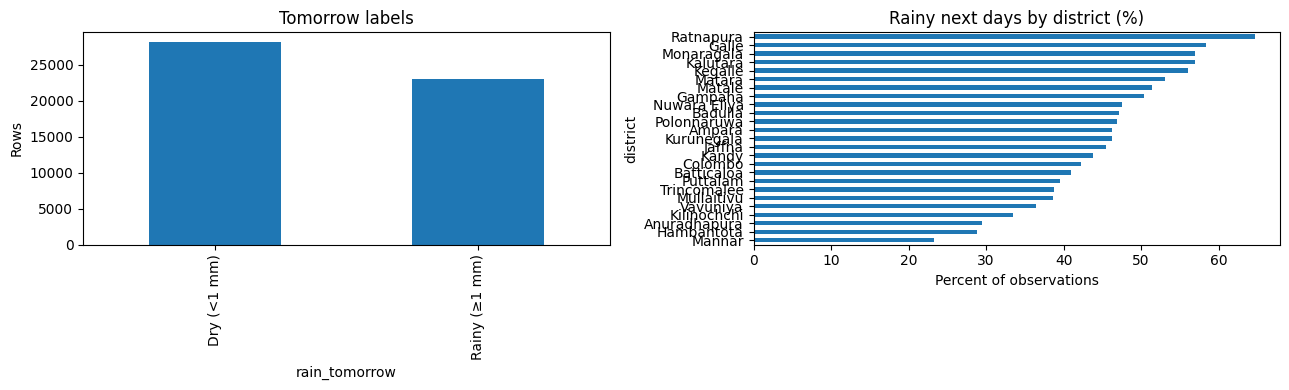

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
data['rain_tomorrow'].map({0:'Dry (<1 mm)',1:'Rainy (≥1 mm)'}).value_counts().plot.bar(ax=axes[0],title='Tomorrow labels')
(data.groupby('district')['rain_tomorrow'].mean().sort_values() * 100).plot.barh(ax=axes[1],title='Rainy next days by district (%)')
axes[0].set_ylabel('Rows'); axes[1].set_xlabel('Percent of observations'); plt.tight_layout();plt.show()

## 5. Chronological split prevents random future-to-past leakage
Training labels: **2020–2023**. Validation labels: **2024**. Final test labels: **2025**. Training the preprocessing pipeline only on the training fold avoids imputation/encoding leakage.

**Why not random train/test split?** A random split would mix near-identical neighboring dates and misrepresent future weather prediction performance.

In [ ]:
train, validation, test = chronological_split(data)
for name, frame in [('Train',train),('Validation',validation),('Test',test)]:
    print(f'{name:<12} {len(frame):>6,} rows  |  date range {frame.target_date.min().date()}—{frame.target_date.max().date()} | rainy={frame.rain_tomorrow.mean():.2%}')
print('Input variables:', FEATURES)
assert train.target_date.max() < validation.target_date.min() < test.target_date.min()

Train        35,403 rows  |  date range 2020-01-02—2023-12-31 | rainy=48.92%
Validation    9,149 rows  |  date range 2024-01-01—2024-12-31 | rainy=40.20%
Test          6,577 rows  |  date range 2025-01-01—2025-09-21 | rainy=30.67%
Input variables: ['district', 'temp', 'humidity', 'precip', 'windspeed', 'rain_3d_total', 'rain_7d_total', 'rainy_days_7d', 'season_sin', 'season_cos']


## 6. Implement ensemble algorithms
**Bagging:** Random Forest (bootstrap samples and feature randomness) decreases variance by averaging trees.

**Boosting:** Histogram Gradient Boosting fits trees sequentially to reduce loss.

**Stacking:** Random Forest + Boosting + Logistic Regression are base learners. Their *out-of-fold* predictions train a Logistic Regression meta-learner. `cv=3` uses regular cross-validation *within the old training years only*, not a purged time-series CV; this is a limitation to disclose. The final year remains untouched.

**Majority-class DummyClassifier** is shown as a sanity baseline, not counted as a fourth ensemble.

The following code cell implements model configuration, preprocessing and evaluation in the notebook itself. If you also use the Streamlit dashboard, its supporting code follows the same model definitions. All methods are scikit-learn classifiers.

In [ ]:
# AI-assisted implementation: preprocessing, bagging, boosting, stacking and evaluation.
ARTIFACTS = BASE / 'artifacts'

def preprocess():
    return ColumnTransformer(transformers=[
        ("numbers", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("district", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL_FEATURES),
    ], remainder="drop", sparse_threshold=0)


def models():
    """Bagging RF; boosted trees; stack trained with OOF predictions within train years."""
    rf = RandomForestClassifier(
        n_estimators=120, max_depth=12, min_samples_leaf=5,
        random_state=42, n_jobs=-1,
    )
    gb = HistGradientBoostingClassifier(
        max_iter=110, learning_rate=0.07, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=42,
    )
    stack = StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(
                n_estimators=80, max_depth=10, min_samples_leaf=5,
                random_state=42, n_jobs=-1,
            )),
            ("boost", HistGradientBoostingClassifier(
                max_iter=80, max_leaf_nodes=13, learning_rate=0.08,
                l2_regularization=1.0, random_state=42,
            )),
            ("linear", LogisticRegression(max_iter=1200, random_state=42)),
        ],
        final_estimator=LogisticRegression(max_iter=1200, random_state=42),
        cv=3, n_jobs=-1,
    )
    return {
        "Bagging — Random Forest": Pipeline([("prep", preprocess()), ("model", rf)]),
        "Boosting — HistGradientBoosting": Pipeline([("prep", preprocess()), ("model", gb)]),
        "Stacking — Meta Logistic": Pipeline([("prep", preprocess()), ("model", stack)]),
        "Baseline — Majority Class": Pipeline([
            ("prep", preprocess()),
            ("model", DummyClassifier(strategy="prior")),
        ]),
    }


def evaluate(model, df: pd.DataFrame) -> dict:
    x, y = df[FEATURES], df["rain_tomorrow"].astype(int)
    proba = model.predict_proba(x)[:, 1]
    labels = (proba >= 0.5).astype(int)
    return {
        "accuracy": round(float(accuracy_score(y, labels)), 4),
        "precision": round(float(precision_score(y, labels, zero_division=0)), 4),
        "recall": round(float(recall_score(y, labels, zero_division=0)), 4),
        "f1": round(float(f1_score(y, labels, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(y, proba)), 4),
        "tn_fp_fn_tp": [int(x) for x in confusion_matrix(y, labels, labels=[0, 1]).ravel()],
        "rain_prevalence": round(float(y.mean()), 4),
        "n_samples": int(len(y)),
    }


def run_experiment(train, validation, test, save=True, verbose=True):
    model_set = models()
    metrics = []
    prediction_frames = []
    for name, model in model_set.items():
        if verbose:
            print(f"Training: {name} ...", flush=True)
        model.fit(train[FEATURES], train["rain_tomorrow"].astype(int))
        for split_name, partition in [("validation_2024", validation), ("test_2025", test)]:
            scores = evaluate(model, partition)
            metrics.append({"model": name, "split": split_name, **scores})
            probs = model.predict_proba(partition[FEATURES])[:, 1]
            prediction_frames.append(pd.DataFrame({
                "date": partition["target_date"].to_numpy(),
                "district": partition["district"].to_numpy(),
                "actual": partition["rain_tomorrow"].to_numpy(),
                "model": name, "probability": probs,
                "prediction": (probs >= 0.5).astype(int),
                "split": split_name,
            }))
    metric_df = pd.DataFrame(metrics)
    predictions = pd.concat(prediction_frames, ignore_index=True)
    if save:
        ARTIFACTS.mkdir(parents=True, exist_ok=True)
        for name, estimator in model_set.items():
            safe = name.split(" — ")[0].lower()
            joblib.dump(estimator, ARTIFACTS / f"{safe}.joblib", compress=3)
        metric_df.to_csv(ARTIFACTS / "metrics.csv", index=False)
        predictions.to_csv(ARTIFACTS / "predictions.csv", index=False)
        summary = {"dataset_rows": len(train) + len(validation) + len(test),
                   "train_rows": len(train), "validation_rows": len(validation),
                   "test_rows": len(test), "rain_threshold_mm": 1.0}
        (ARTIFACTS / "experiment.json").write_text(json.dumps(summary, indent=2))
    return model_set, metric_df, predictions




In [ ]:
fitted, metrics, predictions = run_experiment(train, validation, test, save=True, verbose=True)
print('Training complete. Fitted models and CSV outputs saved to artifacts/.')

Training: Bagging — Random Forest ...
Training: Boosting — HistGradientBoosting ...
Training: Stacking — Meta Logistic ...
Training: Baseline — Majority Class ...
Training complete. Fitted models and CSV outputs saved to artifacts/.


## 7. Evaluate real metrics for validation and unseen test period
For rainy days as the positive class, compare Accuracy, Precision, Recall, F1 and ROC-AUC. Prioritize **F1** when balancing missed rain events and false alarms, but also discuss the specific costs of false negatives and false positives.

In [ ]:
selected = metrics[['model','split','accuracy','precision','recall','f1','roc_auc','n_samples']].copy()
display(selected.sort_values(['split','f1'],ascending=[True,False]).round(3))
test_scores = selected[(selected['split']=='test_2025') & ~selected['model'].str.startswith('Baseline')]
best = test_scores.sort_values('f1', ascending=False).iloc[0]
print('Highest 2025 held-out F1:', best['model'], 'F1 =', round(best['f1'],3))
print('NOTE: This is descriptive test ranking, not a tuning decision. Do not retune on 2025.')

,model,split,accuracy,precision,recall,f1,roc_auc,n_samples
1,Bagging — Random Forest,test_2025,0.739,0.586,0.509,0.545,0.770,6577
3,Boosting — HistGradientBoosting,test_2025,0.728,0.560,0.526,0.543,0.763,6577
5,Stacking — Meta Logistic,test_2025,0.732,0.576,0.477,0.522,0.759,6577
7,Baseline — Majority Class,test_2025,0.693,0.000,0.000,0.000,0.500,6577
2,Boosting — HistGradientBoosting,validation_2024,0.740,0.667,0.707,0.686,0.808,9149
0,Bagging — Random Forest,validation_2024,0.740,0.677,0.675,0.676,0.812,9149
4,Stacking — Meta Logistic,validation_2024,0.732,0.663,0.681,0.672,0.807,9149
6,Baseline — Majority Class,validation_2024,0.598,0.000,0.000,0.000,0.500,9149


Highest 2025 held-out F1: Bagging — Random Forest F1 = 0.545
NOTE: This is descriptive test ranking, not a tuning decision. Do not retune on 2025.


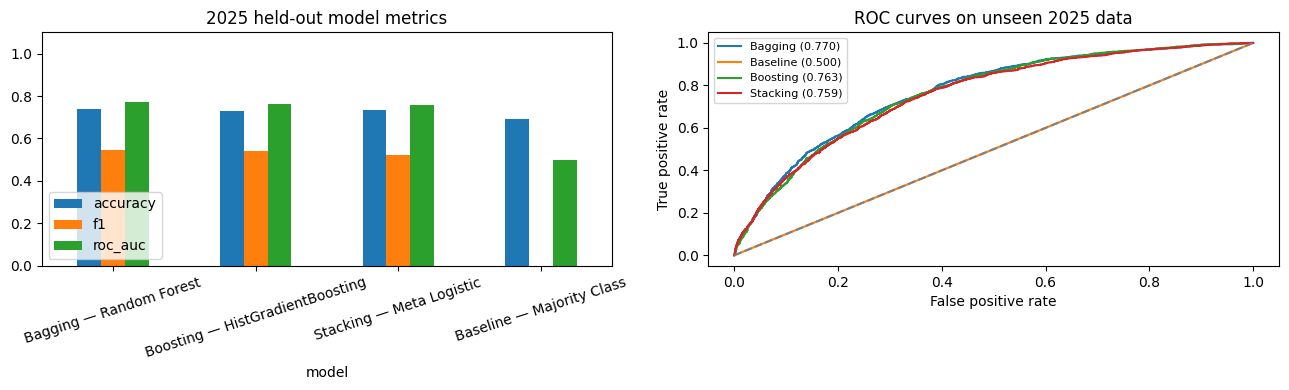

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
metrics.query("split == 'test_2025'").set_index('model')[['accuracy','f1','roc_auc']].plot.bar(ax=axes[0],title='2025 held-out model metrics',ylim=(0,1.1))
axes[0].legend(loc='lower left'); axes[0].tick_params(axis='x',rotation=18)
for name, group in predictions.query("split == 'test_2025'").groupby('model'):
    from sklearn.metrics import roc_curve
    fpr,tpr,_=roc_curve(group.actual,group.probability)
    auc=metrics.loc[(metrics.model==name)&(metrics.split=='test_2025'),'roc_auc'].iloc[0]
    axes[1].plot(fpr,tpr,label=f'{name.split(" — ")[0]} ({auc:.3f})')
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].set_title('ROC curves on unseen 2025 data');axes[1].set_xlabel('False positive rate');axes[1].set_ylabel('True positive rate');axes[1].legend(fontsize=8);plt.tight_layout();plt.show()

In [ ]:
# Inspect how many rainy days were missed and how many dry days were falsely flagged.
rows=metrics.query("split == 'test_2025'")
for _, r in rows.iterrows():
    tn,fp,fn,tp=r['tn_fp_fn_tp']
    print(f'{r["model"]:<36} TN={tn:>5} FP={fp:>5} FN={fn:>5} TP={tp:>5}')

Bagging — Random Forest              TN= 3833 FP=  727 FN=  990 TP= 1027
Boosting — HistGradientBoosting      TN= 3727 FP=  833 FN=  956 TP= 1061
Stacking — Meta Logistic             TN= 3851 FP=  709 FN= 1054 TP=  963
Baseline — Majority Class            TN= 4560 FP=    0 FN= 2017 TP=    0


## 8. Interpretation of Results

### 1. Which model performed best in 2024 and 2025?

In the 2024 validation dataset, **Boosting (HistGradientBoosting)** achieved the highest F1-score of **0.686**.

However, in the 2025 test dataset, **Bagging (Random Forest)** performed slightly better, achieving an F1-score of **0.5447** and an accuracy of **73.89%**.

This shows that model performance can change when tested on data from different years.

### 2. Which model missed fewer rainy days?

Boosting missed the fewest rainy days in the 2025 test dataset.

- Bagging: 990 missed rainy days
- Boosting: 956 missed rainy days
- Stacking: 1,054 missed rainy days

Boosting achieved the highest recall of **52.60%**, meaning it correctly identified a slightly higher proportion of actual rainy days. However, it also produced more false rain predictions than Bagging.

### 3. Did Stacking outperform the other models?

No. Stacking achieved an F1-score of **0.5221**, which was lower than Bagging (0.5447) and Boosting (0.5426).

Combining multiple models does not always improve prediction accuracy. The models may make similar mistakes, and combining their predictions can introduce additional complexity without improving performance.

In this experiment, the simpler Bagging model performed better than Stacking.

### 4. Did the ensemble models improve performance compared to the baseline?

Yes. The majority-class baseline achieved **69.33% accuracy**, while Bagging achieved **73.89% accuracy**, an improvement of **4.56 percentage points**.

However, the baseline predicted every test observation as a dry day. Therefore, its recall and F1-score for rainy days were both zero.

Bagging achieved an F1-score of 0.5447, showing that it was more useful for identifying rainy days. Although the accuracy improvement was modest, detecting rainfall is more meaningful than simply predicting the most common class.

### 5. How do district differences and seasonal changes affect prediction performance?

Sri Lanka has different rainfall patterns across districts such as Jaffna, Colombo and Kandy.

Weather conditions also vary during different monsoon seasons. A model trained using historical patterns may perform differently in another district or season.

The proportion of rainy observations also changed across the datasets:

- Training (2020–2023): 48.92%
- Validation (2024): 40.20%
- Testing (2025): 30.67%

These differences may have contributed to the lower F1-scores in 2025. However, further analysis would be required to confirm the exact reasons.

### 6. What are the limitations of this project?

This project has several limitations.

- **Dataset reliability:** The original source of the weather measurements is not fully documented, so their accuracy cannot be independently verified.
- **Limited input features:** The models use current and historical weather information but do not include future weather forecast variables.
- **Data correlations:** Weather observations from nearby dates or districts may be correlated, potentially affecting model evaluation.
- **Probability calibration:** The predicted probabilities have not been formally calibrated, so they should not be interpreted as verified rainfall probabilities.
- **Stacking validation:** The Stacking model uses ordinary cross-validation internally instead of time-series cross-validation, which may affect its reliability for sequential weather data.
- **Testing period:** The 2025 test dataset only covers observations up to September 2025, not the complete year.

### Final Conclusion

The experiment successfully compared Bagging, Boosting and Stacking for predicting next-day rainfall in Sri Lanka.

**Bagging (Random Forest) achieved the best overall 2025 test performance**, with 73.89% accuracy and an F1-score of 0.5447.

Boosting detected slightly more rainy days, while Stacking did not improve overall performance.

The results demonstrate that more complex ensemble methods do not always produce better predictions. Model selection should consider multiple evaluation metrics, the dataset characteristics and the practical purpose of the prediction.

## 9. References and AI Usage

### References

1. **Dataset:** Sri Lanka Weather Dataset (2020–2025).  
   https://github.com/Lahirulakshan129/SriLanka-Weather-Dataset

2. **Machine Learning Library:** Scikit-learn documentation – Ensemble Methods.  
   https://scikit-learn.org/stable/modules/ensemble.html

### AI Assistance Declaration

OpenAI ChatGPT (GPT-6, accessed 22 November 2026) was used to assist with Python code development, data preprocessing, ensemble model implementation, dashboard creation, and documentation.

The models were executed and evaluated using the Sri Lankan weather dataset. The generated results were reviewed, and the model comparisons and conclusions are explained as part of the assignment.